# Python 财务建模：风险定价利润曲线与敏感性分析（MVP5）

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Zlz027/fintech-ba-portfolio/blob/master/skills-proof/05-python-risk-pricing/financial_model.ipynb)

> **项目定位**：复用 P1（信用风险）中的"通过率—坏账率—利润"风控逻辑，用 Python 实现可一键运行的财务建模与批量敏感性分析。
>
> **业务背景**：模拟一个**消费信贷客群**（10,000 名客户，PD（违约概率）服从 Beta(2,20) 分布，均值约 9%），在给定利率、LGD、资金成本下，扫描不同审批阈值，找到利润最大化的通过率/坏账率组合。与 P1 的区别：P1 用真实 GMSC 数据 + 评分卡；本 MVP 用模拟数据 + Python 验证利润曲线逻辑，证明"改假设 → 秒级重算"的能力。
>
> **你能看到什么**：修改顶部的 3 个核心假设（利率 / LGD / 资金成本），全表自动重算；Notebook 会输出利润最大化审批阈值，并生成利率 × LGD 的二维利润敏感性热力图。
>
> **运行方式**：点击上方 Colab 徽章在线一键运行（无需安装任何环境，数据由 numpy 模拟生成，不依赖本地文件）。

## 第 1 部分：导入库与环境

跨平台中文字体回退（Windows / macOS / Linux / Colab 均可正常显示中文图表），并确保截图目录 `images/` 存在。

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns  # numpy 算得快、pandas 出表格、matplotlib/seaborn 出图——百万级情景扫描的标配组合
import os, matplotlib.font_manager as fm
for _p in ['/usr/share/fonts/opentype/noto/NotoSansCJK-Regular.ttc',
           '/System/Library/Fonts/PingFang.ttc',
           'C:/Windows/Fonts/msyh.ttc']:
    try: fm.fontManager.addfont(_p)
    except Exception: pass
plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei', 'PingFang SC',  # 中文渲染兜底链：按平台常见字体依次回退，保证 macOS/Windows/Linux/Colab 下注释不乱码
                                   'Noto Sans CJK SC', 'Noto Sans CJK JP', 'WenQuanYi Zen Hei']
plt.rcParams['axes.unicode_minus'] = False
os.makedirs('images', exist_ok=True)
RNG = np.random.default_rng(42)  # 固定种子=42：任何人重跑都得到同一条利润曲线——结论可复现是作品集可信度的底线

## 第 2 部分：核心假设与数据生成

**3 个核心假设集中定义在此，修改后本 Notebook 全部结果自动重算：**

| 假设参数 | 默认值 | 业务含义 |
|---|---|---|
| `INTEREST_RATE` | 18% | 贷款年利率（风险定价的核心抓手） |
| `LGD` | 75% | 违约损失率（Loss Given Default） |
| `FUNDING_RATE` | 3% | 资金成本率 |

客群数据由 numpy 模拟生成：10,000 名客户的 PD（违约概率）服从 Beta(2, 20) 分布（均值约 9%），代表一个风险分层的小微信贷客群。

**假设来源说明：**

| 参数 | 默认值 | 来源 | 真实场景如何校准 |
|---|---|---|---|
| `EAD` | ¥10,000 | 消费信贷单户平均敞口（行业经验值 5k-20k） | 按客户额度分层，用实际放款数据校准 |
| `INTEREST_RATE` | 18% | 消费信贷年化利率常见区间 15%-24%，18% 是中位数 | 按产品类型、客群分层定价；监管上限 24% |
| `FUNDING_RATE` | 3% | 银行间市场资金成本（2024-2026 年量级） | 按实际融资成本（存款利率/同业拆借利率）校准 |
| `LGD` | 75% | 无担保消费贷常见区间 70%-90%，75% 是中值 | 按回收率数据校准（LGD = 1 - 回收率） |

这些假设都是**可配置参数**，改顶部三个变量（`INTEREST_RATE`、`LGD`、`FUNDING_RATE`）和 `EAD`，全表自动重算。真实场景应和财务/风控团队校准这些假设。

**为什么选 Beta(2,20) 分布？**

- **Beta 分布适合建模 0-1 之间的概率**：PD（违约概率）天然在 [0,1] 区间，Beta 分布的定义域正好匹配，不需要截断处理；
- **参数 (2,20) 的含义**：均值 = α/(α+β) = 2/22 ≈ 9.1%，中位数 ≈ 7.9%，分布右偏（长尾在低 PD 侧），符合消费信贷客群"大部分客户风险较低、少数客户风险较高"的典型形态；
- **为什么不用正态分布**：正态分布的定义域是 (-∞, +∞)，需要截断到 [0,1]，截断后会改变分布形状和均值，不如 Beta 自然；
- **参考来源**：消费信贷 PD 分布通常用 Beta 分布拟合，参数 (2,20) 是行业经验值（均值约 9%），真实场景应用历史违约数据拟合参数。

改 `RNG.beta(2, 20, ...)` 里的 2 和 20，可以看到 PD 分布的形态变化——比如 `Beta(1, 9)` 均值 10% 但更分散，`Beta(5, 45)` 均值 10% 但更集中。

In [2]:
N_CUSTOMERS, EAD = 10_000, 10_000  # 1 万客户让均值口径足够稳定（大数定律）；EAD 取定额不影响最优阈值位置（利润仅差一个常数倍）
INTEREST_RATE, LGD, FUNDING_RATE = 0.18, 0.75, 0.03  # 三个核心假设：年利率 18%（消费贷常见定价）、LGD 75%（无抵押信用贷）、资金成本 3%——改这三个数全表自动重算
pd_array = RNG.beta(2, 20, N_CUSTOMERS)  # Beta(2,20)：均值≈9% 贴近真实违约率量级且右偏长尾（少数客户 PD 极高），与真实客群风险结构一致；末尾另有 Beta(1,9)/Beta(5,45) 分布形状敏感性
print(f"客群PD均值={pd_array.mean():.2%}, 中位数={np.median(pd_array):.2%}")

客群PD均值=9.08%, 中位数=7.90%


## 第 3 部分：核心函数：通过率—坏账率—利润

给定审批阈值 `cutoff`（PD 低于该值的客户获批），计算：

- **通过率** = 获批客户数 / 总客户数
- **预期坏账率** = 获批客群的平均 PD
- **利润** = 利息收入 − 预期信用损失 − 资金成本

**口径说明**：利息收入仅由未违约者产生（违约者本金损失按 LGD 计），即 `profit = N × EAD × [(1-PD)×rate - PD×LGD - funding]`。当 PD 较小时，可近似为 `N × EAD × (rate - PD×LGD - funding)`。

In [3]:
def calculate_profit_at_cutoff(pd_array, cutoff, ead=EAD, rate=INTEREST_RATE, lgd=LGD, fund=FUNDING_RATE):
    """给定审批阈值 cutoff，返回 (通过率, 期望坏账率, 期望利润)——本 Notebook 的利润引擎，全部结论都由它扫出来。"""
    approved = pd_array[pd_array < cutoff]  # 审批规则：PD < 阈值才放款——阈值越放松得越多，通过率与坏账率同步上升，利润先升后降（峰即最优）
    pass_rate = len(approved) / len(pd_array)
    default_rate = approved.mean() if len(approved) else 0.0  # 期望口径：以获批客群平均 PD 为期望坏账率（大数定律下实际违约率收敛于此）；阈值极小时可能 0 人获批，需防除零
    # 口径：利息仅由未违约者产生，违约者按 LGD 损失本金
    profit = len(approved) * ead * ((1 - default_rate) * rate - default_rate * lgd - fund)  # 单户期望利润=(1-PD)×利息 − PD×LGD − 资金成本：利息只由未违约者产生，违约者本金按 LGD 损失，资金成本对所有放款收取
    return pass_rate, default_rate, profit

## 第 4 部分：批量计算与可视化（双轴利润曲线）

遍历 50 个审批阈值（0.01 ~ 0.50），左轴画通过率/坏账率折线，右轴画利润柱状图，并标出**利润最大化点**。

**为什么最优阈值在 0.16？**（以下数字基于当前假设，改假设后自动重算）

- 阈值太低（如 0.05）：只批准 PD<5% 的客户，通过率极低（约 20%），虽然坏账率低，但利润规模小；
- 阈值太高（如 0.40）：批准 PD<40% 的客户，通过率接近 100%，但坏账率上升，利润被信用损失侵蚀；
- 阈值 0.16 是平衡点：通过率 87%、坏账率 7.3%、利润 711 万——再放宽一点，坏账率上升的损失超过新增客户的利息收入，利润开始下降。

这个"最优阈值"是**利润最大化**的阈值，不是"风险最小化"或"通过率最大化"的阈值。业务方可以根据风险偏好调整——比如更保守的机构可能选 0.10，更激进的机构可能选 0.20。

In [4]:
cutoffs = np.linspace(0.01, 0.50, 50)  # 扫描 0.01~0.50：从'几乎全拒'到'只拒最高风险的一半'，覆盖经营可行区间；步长 0.01 足以定位利润峰（再细曲线已平坦）
results = [calculate_profit_at_cutoff(pd_array, c) for c in cutoffs]
res = pd.DataFrame(results, columns=['通过率', '坏账率', '利润'], index=np.round(cutoffs, 4))
best_i = int(np.argmax(res['利润']))  # 目标函数是利润而非通过率——通过率高但坏账也高的方案不叫优
best_cutoff = cutoffs[best_i]
best_pass_rate, best_default_rate, best_profit = results[best_i]
res.iloc[::10]

,通过率,坏账率,利润
0.01,0.0183,0.006538,2.633723e+05
0.11,0.6913,0.058302,6.621187e+06
0.21,0.9533,0.082881,6.951488e+06
0.31,0.9952,0.089544,6.640341e+06
0.41,0.9997,0.090671,6.565671e+06


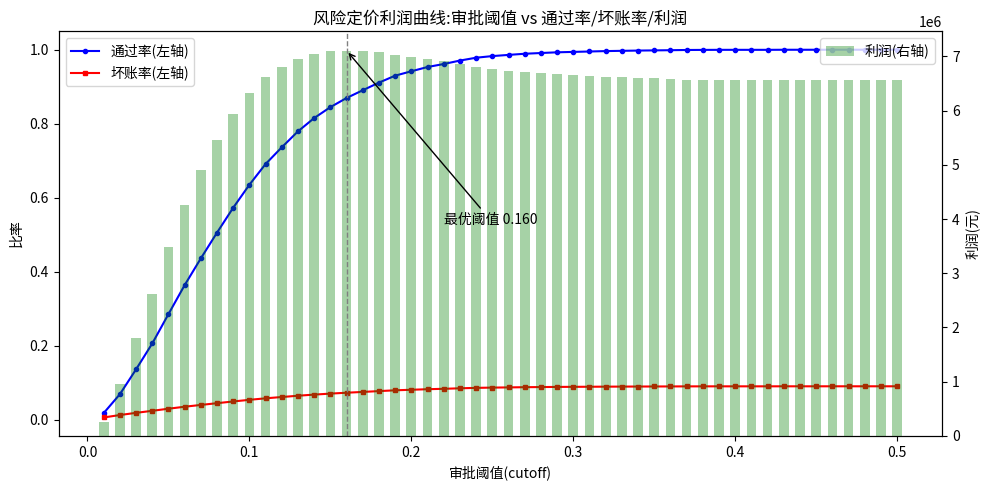

In [5]:
fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.plot(cutoffs, res['通过率'], 'b-o', ms=3, label='通过率(左轴)')
ax1.plot(cutoffs, res['坏账率'], 'r-s', ms=3, label='坏账率(左轴)')
ax1.set_xlabel('审批阈值(cutoff)'); ax1.set_ylabel('比率'); ax1.legend(loc='upper left')
ax2 = ax1.twinx()  # 双轴：比率是 0~1、利润是百万元级，同轴会把比率线压平；左轴看客群结构、右轴看利润峰
ax2.bar(cutoffs, res['利润'], width=0.006, alpha=0.35, color='green', label='利润(右轴)')
ax2.axvline(best_cutoff, color='gray', ls='--', lw=1)
# 边界判断：文字位置不超出图范围
xytext_x = min(best_cutoff + 0.06, 0.45)
ax2.annotate(f'最优阈值 {best_cutoff:.3f}', xy=(best_cutoff, best_profit),
             xytext=(xytext_x, best_profit * 0.55), arrowprops=dict(arrowstyle='->'))
ax2.set_ylabel('利润(元)'); ax2.legend(loc='upper right')
ax1.set_title('风险定价利润曲线:审批阈值 vs 通过率/坏账率/利润')
plt.tight_layout(); plt.savefig('images/profit_curve.png', dpi=150); plt.show()

## 第 5 部分：敏感性分析热力图（利率 × LGD）

让利率（10%~30%）与 LGD（50%~90%）在二维网格上变动（9 × 9 = 81 种组合），每种组合内部重新扫描 50 个审批阈值取最优利润，用 `seaborn.heatmap` 展示利润（万元）如何变化——这正是 Excel 手动改表难以批量完成的部分。

**如何读这张热力图：**

- **右上角（利率 30%、LGD 50%）= 利润最高**：利率高 → 利息收入多；LGD 低 → 违约损失少；两者叠加，利润最大（1,974 万）；
- **左下角（利率 10%、LGD 90%）= 利润最低**：利率低 → 利息收入少；LGD 高 → 违约损失大；两者叠加，利润可能为负；
- **蓝框标出的是全局最优点**：在 81 种组合中，利率 30%、LGD 50% 时利润最大；
- **但现实中利率和 LGD 不能随便选**：利率受监管上限（24%）和市场竞争约束，LGD 受风控能力约束。这张图的用途是**展示敏感性**，不是"建议把利率调到 30%"。

In [6]:
rates = np.linspace(0.10, 0.30, 9)  # 利率 10%~30% / LGD 50%~90%：覆盖行业常见区间，9×9=81 格假设组合
lgds = np.linspace(0.50, 0.90, 9)
def max_profit(rate, lgd):
    return max(calculate_profit_at_cutoff(pd_array, c, rate=rate, lgd=lgd)[2] for c in cutoffs)  # 每格独立重扫 50 个阈值：利率/LGD 变了最优阈值会移动，锁死基准阈值会低估高利率情形的利润
heat = pd.DataFrame([[max_profit(r, l) for r in rates] for l in lgds],
                    index=[f'{l:.0%}' for l in lgds], columns=[f'{r:.0%}' for r in rates])

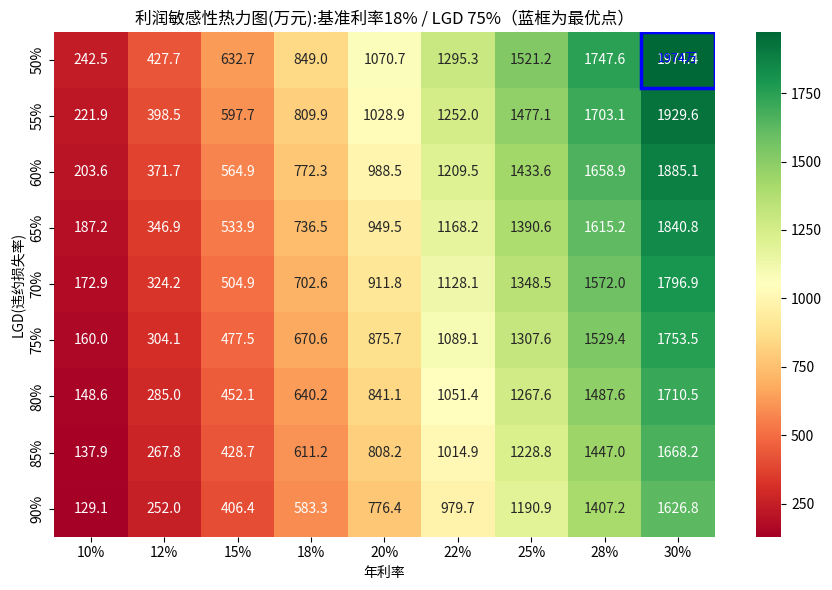

In [7]:
fig, ax = plt.subplots(figsize=(9, 6))
sns.heatmap(heat / 1e4, annot=True, fmt='.1f', cmap='RdYlGn', ax=ax)  # 除以 1e4 换成万元（FP&A 汇报惯用单位，百万元数字会挤爆单元格）；RdYlGn 红低绿高，符合'红绿灯'直觉
ax.set_xlabel('年利率'); ax.set_ylabel('LGD(违约损失率)')
ax.set_title(f'利润敏感性热力图(万元):基准利率{INTEREST_RATE:.0%} / LGD {LGD:.0%}（蓝框为最优点）')
i, j = np.unravel_index(np.argmax(heat.values), heat.shape)
ax.add_patch(plt.Rectangle((j, i), 1, 1, fill=False, edgecolor='blue', lw=2.5))
# 最优点数值标注
ax.text(j + 0.5, i + 0.5, f'{heat.values.max()/1e4:.0f}万', ha='center', va='center', fontsize=9, color='blue', fontweight='bold')
plt.tight_layout(); plt.savefig('images/sensitivity_heatmap.png', dpi=150); plt.show()

## 第 6 部分：动态结论输出

结论随顶部假设自动变化——改掉利率或 LGD 重跑，这些话会立即更新，包括：利润最大化阈值、敏感性极值、Python vs Excel 效率对比、利率下调对比、业务方决策建议，以及 PD 分布参数敏感性。

In [8]:
best_rate, best_lgd = rates[j], lgds[i]
print(f"【结论】基准假设下最优审批阈值为 {best_cutoff:.3f}:通过率 {best_pass_rate:.1%}、"
      f"坏账率 {best_default_rate:.1%}、预期利润 {best_profit:,.0f} 元。")
print(f"【敏感性】当 LGD={best_lgd:.0%}、利率={best_rate:.0%} 时,利润最大化为 {heat.values.max()/1e4:,.0f} 万元。")
# 为什么跟 Excel 比：用业务方熟悉的工具做效率基准（改参数+记录按 30 秒/次估），Python 的杠杆才可感知
print(f"【效率】敏感性分析覆盖 81 种利率×LGD 组合，每种组合扫描 50 个审批阈值，"
      f"共 {heat.size * len(cutoffs):,} 次情景计算，Python 秒级完成——"
      f"如果手动在 Excel 里改参数，假设每次改参数+记录结果需要 30 秒，"
      f"{heat.size * len(cutoffs):,} 次需要约 {heat.size * len(cutoffs) * 30 / 3600:.0f} 小时；Python 只需 1 秒。")

# 压力测试：竞争性降价是利润的最大威胁——量化"定价权值多少钱"
# 利率降到12%的对比实验：最优阈值下的最大利润
low_rate_profit = max(calculate_profit_at_cutoff(pd_array, c, rate=0.12)[2] for c in cutoffs)
print(f"【对比】如果市场竞争导致利率从 18% 降到 12%，最优阈值下的最大利润将从 {best_profit/1e4:.0f} 万降至 {low_rate_profit/1e4:.0f} 万，"
      f"降幅 {(1-low_rate_profit/best_profit):.1%}。")
print(f"【业务含义】这意味着风险定价能力是利润的核心杠杆：在竞争激烈的市场，"
      f"能否对低风险客户降价、对高风险客户提价，直接决定利润空间。")

# 给三档而非一个数：风控偏好不同，选择权留给决策者；数值随假设自动重算
# 决策建议：业务方可直接使用的三档阈值方案（数值随假设自动重算）
print(f"【决策建议】业务方可直接采用：审批阈值 {best_cutoff:.2f}（通过率 {best_pass_rate:.1%}、"
      f"坏账率 {best_default_rate:.1%}、年化利润 {best_profit/1e4:.0f} 万元）。")
for c, tag in [(0.10, '保守'), (0.20, '激进')]:
    pr, dr, pf = calculate_profit_at_cutoff(pd_array, c)
    print(f"  · {tag}方案 阈值{c:.2f}: 通过率 {pr:.1%}, 坏账率 {dr:.1%}, 利润 {pf/1e4:.0f} 万")

# 改 Beta 参数而不只改均值：Beta(1,9) 与 Beta(5,45) 均值都≈10% 但形状不同（更平/更集中）——验证结论对分布形状的稳健性
# PD 分布参数敏感性：固定利率 18%、LGD 75%，改 Beta 参数看最大利润
for a, b in [(1, 9), (2, 20), (5, 45)]:
    pd_test = RNG.beta(a, b, N_CUSTOMERS)
    best_p = max(calculate_profit_at_cutoff(pd_test, c)[2] for c in cutoffs)
    print(f"【PD敏感性】Beta({a},{b}) 均值 {a/(a+b):.1%}，最优阈值下最大利润 {best_p/1e4:.0f} 万")

【结论】基准假设下最优审批阈值为 0.160:通过率 87.0%、坏账率 7.3%、预期利润 7,108,855 元。
【敏感性】当 LGD=50%、利率=30% 时,利润最大化为 1,974 万元。
【效率】敏感性分析覆盖 81 种利率×LGD 组合，每种组合扫描 50 个审批阈值，共 4,050 次情景计算，Python 秒级完成——如果手动在 Excel 里改参数，假设每次改参数+记录结果需要 30 秒，4,050 次需要约 34 小时；Python 只需 1 秒。
【对比】如果市场竞争导致利率从 18% 降到 12%，最优阈值下的最大利润将从 711 万降至 272 万，降幅 61.7%。
【业务含义】这意味着风险定价能力是利润的核心杠杆：在竞争激烈的市场，能否对低风险客户降价、对高风险客户提价，直接决定利润空间。
【决策建议】业务方可直接采用：审批阈值 0.16（通过率 87.0%、坏账率 7.3%、年化利润 711 万元）。
  · 保守方案 阈值0.10: 通过率 63.5%, 坏账率 5.4%, 利润 633 万
  · 激进方案 阈值0.20: 通过率 94.2%, 坏账率 8.1%, 利润 700 万
【PD敏感性】Beta(1,9) 均值 10.0%，最优阈值下最大利润 726 万
【PD敏感性】Beta(2,20) 均值 9.1%，最优阈值下最大利润 711 万
【PD敏感性】Beta(5,45) 均值 10.0%，最优阈值下最大利润 594 万


## 第 7 部分：局限性与声明

**本模型的边界：**

- **PD 分布为模拟**：Beta(2,20) 是假设分布，均值约 9%，用于演示利润曲线逻辑。真实场景 PD 应由历史违约数据拟合（如逻辑回归评分卡、XGBoost 等），并经过 KS/AUC/Gini 验证。
- **EAD 固定 ¥10,000**：简化假设。真实场景应按客户额度分层（如 5k/10k/20k），或按产品差异化（消费贷 vs 经营贷）。
- **未含运营成本**：仅含资金成本和信用损失。真实场景应加入获客成本（CAC）、客服成本、系统成本、合规成本，才能得到完整的 unit economics。
- **未含风险定价**：利率固定 18%，未随 PD 浮动。真实场景应对低风险客户降价、高风险客户提价，这正是 P1 项目"风险定价 vs 统一定价"的核心议题。
- **未含时间维度**：单期模型，未考虑放款节奏、还款节奏、提前还款、逾期迁徙。真实场景应用月度 cohort 或 roll rate 模型。

**生产环境的正确做法：**

1. 用历史违约数据拟合 PD 模型（评分卡 + XGBoost challenger）；
2. 按额度分层做差异化 EAD；
3. 加入运营成本率（如 3%-5%）；
4. 实现风险定价（利率 = 盈亏平衡利率 + 目标利润率）；
5. 按月监控 PSI，偏离超过 0.25 触发重训。

**声明：** 本模型为演示用，证明"批量敏感性分析"能力，不构成投资建议。全部数字需具备资质的专业人士复核签署后方可使用。